In [1]:
import pandas as pd
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, classification_report
# ================= PERMUTATION IMPORTANCE =================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance


# ================= SETTINGS =================
IN_PATH = r"C:\Users\salma\Documents\GitHub\Machine-Learning\data\processed\H2_regression_cleaned.csv"   # your input file
OUT_PATH = r"C:\Users\salma\Documents\GitHub\Machine-Learning\data\processed\H2_clean.csv"         # new cleaned file
DROP_DUPLICATES = True      # harmless if your file has no duplicates left
TARGET = "IsCanceled"

# ================= 1. LOAD + FIX NULLS =================
df = pd.read_csv(IN_PATH)
df.columns = df.columns.str.strip()

text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].str.strip()                                    # remove spaces
df[text_cols] = df[text_cols].replace(r"(?i)^null$", np.nan, regex=True)  # "NULL"/"null" -> NaN
print("Real nulls per column:\n", df.isnull().sum()[df.isnull().sum() > 0])

# ================= 2. DROP LEAKAGE =================
df = df.drop(columns=["ReservationStatus", "ReservationStatusDate", "AssignedRoomType"])

# ================= 3. MISSING VALUES =================
df["Children"] = df["Children"].fillna(0)
df["Country"] = df["Country"].fillna("Unknown")
df["has_agent"] = df["Agent"].notna().astype(int)
print("has_agent:\n", df["has_agent"].value_counts())    # must show 0 and 1
df = df.drop(columns=["Agent", "Company"])

# ================= 4. INVALID ROWS =================
df["total_guests"] = df["Adults"] + df["Children"] + df["Babies"]
df["total_nights"] = df["StaysInWeekendNights"] + df["StaysInWeekNights"]
df = df[(df["total_guests"] > 0) & (df["total_nights"] > 0)]   # keep other zeros
df = df[(df["Babies"] <= 5) & (df["ADR"] < 1000)]

# ================= 5. ONE DATE FEATURE =================
months = {m: i for i, m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], 1)}
df["arrival_date"] = pd.to_datetime(dict(
    year=df["ArrivalDateYear"],
    month=df["ArrivalDateMonth"].map(months),
    day=df["ArrivalDateDayOfMonth"]))
df["arrival_days"] = (df["arrival_date"] - df["arrival_date"].min()).dt.days
df = df.drop(columns=["ArrivalDateYear", "ArrivalDateMonth",
                      "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth"])

# ================= 6. OTHER FEATURES =================
df["has_children"] = ((df["Children"] + df["Babies"]) > 0).astype(int)
df["adr_per_person"] = df["ADR"] / df["total_guests"]
df["is_prev_canceller"] = (df["PreviousCancellations"] > 0).astype(int)

keep = df["Country"].value_counts().nlargest(15).index
df["Country"] = df["Country"].where(df["Country"].isin(keep), "Other")

if DROP_DUPLICATES:
    df = df.drop_duplicates()

# ================= 7. SAVE NEW CSV =================
assert df.isnull().sum().sum() == 0, "There are still nulls!"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH, df.shape)

# ================= 8. LOAD CLEAN CSV + SPLIT =================
df = pd.read_csv(OUT_PATH, parse_dates=["arrival_date"])
y = df[TARGET]
X = df.drop(columns=[TARGET, "arrival_date"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1,
                            class_weight="balanced", random_state=42)
pipe = Pipeline([("prep", pre), ("rf", rf)])
pipe.fit(X_train, y_train)

proba = pipe.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pipe.predict(X_test), digits=3))

# ================= 9. PERMUTATION IMPORTANCE =================
perm = permutation_importance(pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, n_jobs=-1, random_state=42)

imp = pd.Series(perm.importances_mean, index=X_test.columns)
err = pd.Series(perm.importances_std, index=X_test.columns)

# table (always shown)
table = pd.DataFrame({"importance": imp, "std": err}).sort_values("importance", ascending=False)
print(table.round(4))

# plot
imp_sorted = imp.sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
imp_sorted.plot.barh(xerr=err[imp_sorted.index], ax=ax)
ax.set_title("Permutation importance (test set, ROC-AUC drop)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
fig.tight_layout()
plt.show()
perm = permutation_importance(pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, n_jobs=-1, random_state=42)

imp = pd.Series(perm.importances_mean, index=X_test.columns)
err = pd.Series(perm.importances_std, index=X_test.columns)

# table (always shown)
table = pd.DataFrame({"importance": imp, "std": err}).sort_values("importance", ascending=False)
print(table.round(4))

# plot
imp_sorted = imp.sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
imp_sorted.plot.barh(xerr=err[imp_sorted.index], ax=ax)
ax.set_title("Permutation importance (test set, ROC-AUC drop)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
fig.tight_layout()
plt.show()

perm = permutation_importance(pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, n_jobs=-1, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
err = pd.Series(perm.importances_std, index=X_test.columns)[imp.index]

fig, ax = plt.subplots(figsize=(9, 8))
imp.plot.barh(xerr=err, ax=ax)
ax.set_title("Permutation importance (test set, ROC-AUC drop)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
fig.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).head(10))

Real nulls per column:
 Country       3
Agent      5526
dtype: int64
has_agent:
 has_agent
1    47524
0     5526
Name: count, dtype: int64


KeyError: "['Company'] not found in axis"

In [4]:
df = pd.read_csv("C:\\Users\\salma\\Documents\\GitHub\\Machine-Learning\\data\\raw\\H2.csv")

In [15]:
df[df['Company'].str.contains("NULL")]['Company'].iloc[0]

'       NULL'

Test accuracy: 0.814


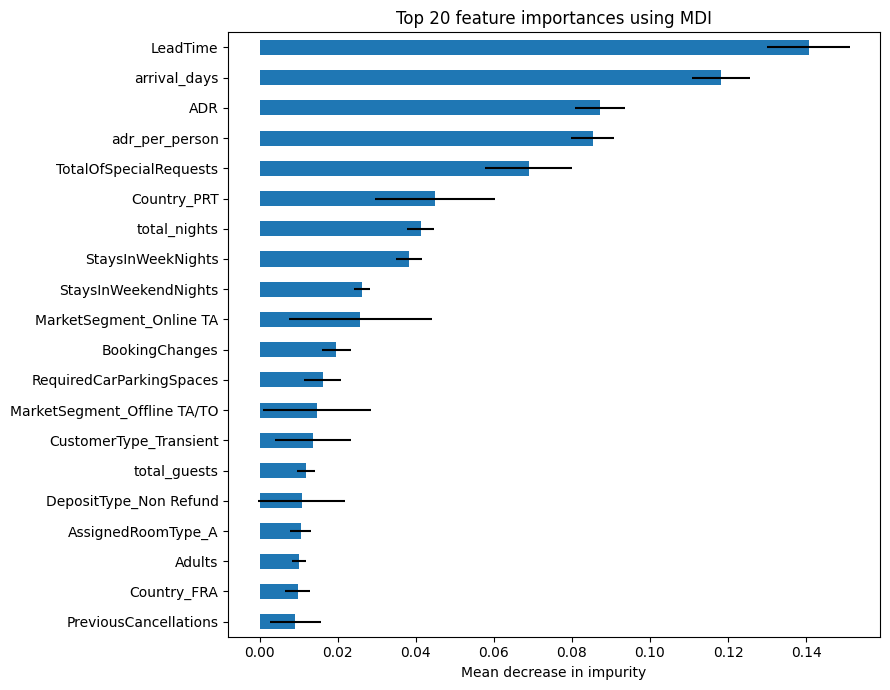

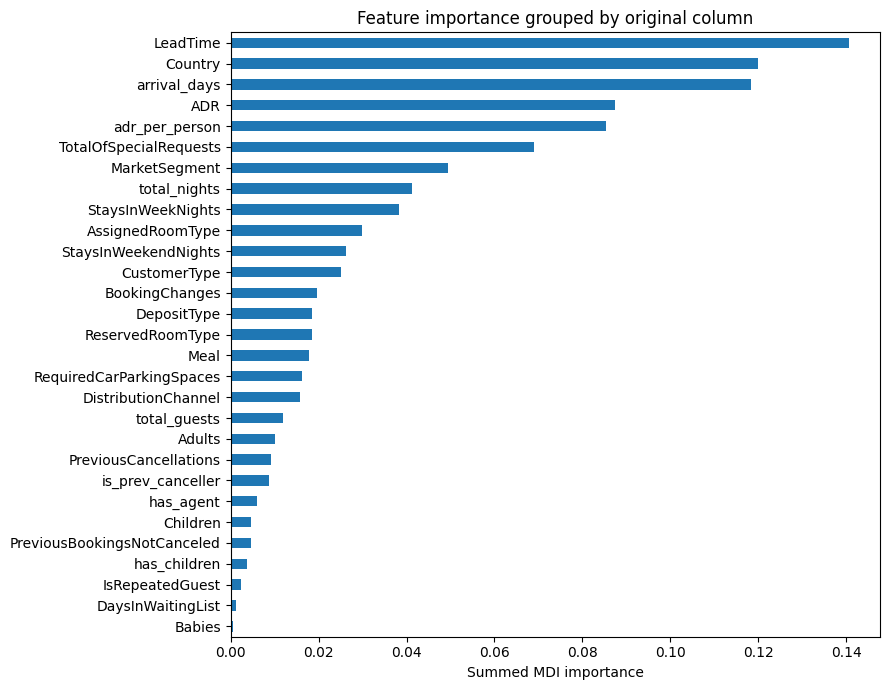

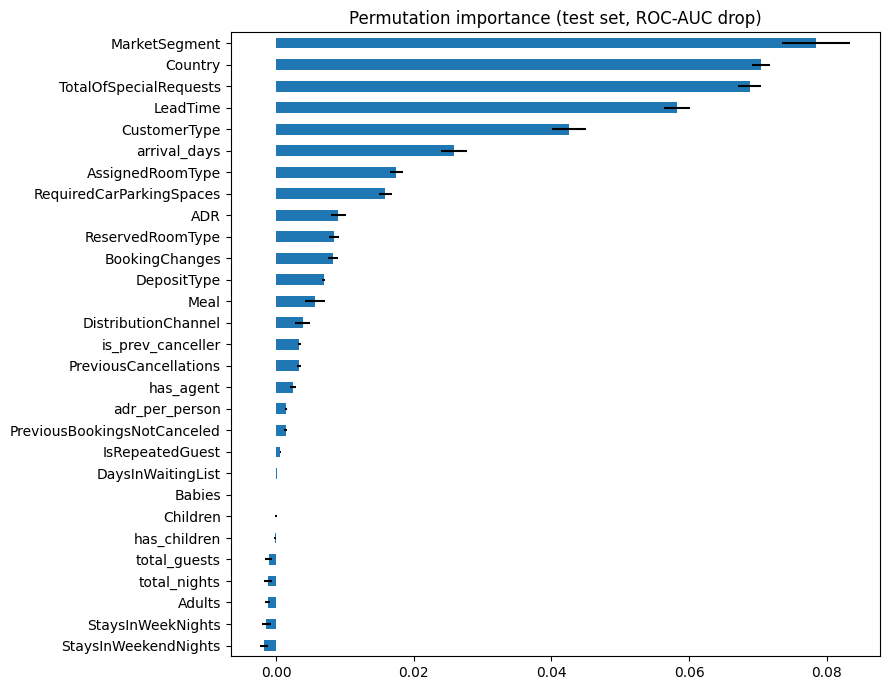

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

# ---------- 1. Load the cleaned CSV ----------
df = pd.read_csv(r"C:\Users\salma\Documents\GitHub\Machine-Learning\data\processed\H2_clean.csv", parse_dates=["arrival_date"])

# ---------- 2. Target and features ----------
TARGET = "IsCanceled"
y = df[TARGET]
X = df.drop(columns=[TARGET, "arrival_date"])   # arrival_days stays as the date feature

# ---------- 3. Split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# ---------- 4. Encode + scale (fit on train only) ----------
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

# ---------- 5. Train the random forest ----------
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1,
                            class_weight="balanced", random_state=42)
rf.fit(X_train_p, y_train)
print("Test accuracy:", round(rf.score(X_test_p, y_test), 3))

# ---------- 6. MDI importances (top 20) ----------
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
importances = pd.Series(rf.feature_importances_, index=feature_names)
std = pd.Series(np.std([t.feature_importances_ for t in rf.estimators_], axis=0),
                index=feature_names)

top = importances.nlargest(20).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
top.plot.barh(xerr=std[top.index], ax=ax)
ax.set_title("Top 20 feature importances using MDI")
ax.set_xlabel("Mean decrease in impurity")
fig.tight_layout()
plt.show()

# ---------- 7. Importance grouped by original column ----------
orig_cols = X_train.columns.tolist()

def original_name(feat):
    if feat in orig_cols:
        return feat
    return next(c for c in sorted(orig_cols, key=len, reverse=True)
                if feat.startswith(c + "_"))

grouped = importances.groupby(original_name).sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
grouped.plot.barh(ax=ax)
ax.set_title("Feature importance grouped by original column")
ax.set_xlabel("Summed MDI importance")
fig.tight_layout()
plt.show()

# ---------- 8. Permutation importance on the test set ----------
pipe = Pipeline([("prep", preprocessor), ("rf", rf)])
perm = permutation_importance(pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, n_jobs=-1, random_state=42)
perm_mean = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_std = pd.Series(perm.importances_std, index=X_test.columns)[perm_mean.index]

fig, ax = plt.subplots(figsize=(9, 7))
perm_mean.plot.barh(xerr=perm_std, ax=ax)
ax.set_title("Permutation importance (test set, ROC-AUC drop)")
fig.tight_layout()
plt.show()

In [9]:
# count the nulls in each column for col in df.columns:

for col in df.columns:
    null_count = df[col].isnull().sum()
    print(f"Column '{col}' has {null_count} null values.")

Column 'IsCanceled' has 0 null values.
Column 'LeadTime' has 0 null values.
Column 'ArrivalDateYear' has 0 null values.
Column 'ArrivalDateMonth' has 0 null values.
Column 'ArrivalDateWeekNumber' has 0 null values.
Column 'ArrivalDateDayOfMonth' has 0 null values.
Column 'StaysInWeekendNights' has 0 null values.
Column 'StaysInWeekNights' has 0 null values.
Column 'Adults' has 0 null values.
Column 'Children' has 4 null values.
Column 'Babies' has 0 null values.
Column 'Meal' has 0 null values.
Column 'Country' has 24 null values.
Column 'MarketSegment' has 0 null values.
Column 'DistributionChannel' has 0 null values.
Column 'IsRepeatedGuest' has 0 null values.
Column 'PreviousCancellations' has 0 null values.
Column 'PreviousBookingsNotCanceled' has 0 null values.
Column 'ReservedRoomType' has 0 null values.
Column 'AssignedRoomType' has 0 null values.
Column 'BookingChanges' has 0 null values.
Column 'DepositType' has 0 null values.
Column 'Agent' has 0 null values.
Column 'Company'